In [1]:
import pandas as pd
import numpy as np

In [32]:
df = pd.read_csv("spam2.csv")

In [34]:
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:", df.columns.tolist())

Dataset shape: (376850, 3)


,message,label,ai_generated
0,"True. I'll try it in browser, then check again...",0,0
1,Free anytime? Let's hit Orchard for Christmas ...,0,1
2,thats the logistical information of legion und...,0,0
3,IM NOT CLOSETED,0,0
4,Same with shotguns,0,0



Column names: ['message', 'label', 'ai_generated']


### removing ai_generated column

In [5]:
df = df.drop(columns=["ai_generated"])

print(df.columns.tolist())
display(df.head())

['message', 'label']


,message,label
0,"True. I'll try it in browser, then check again...",0
1,Free anytime? Let's hit Orchard for Christmas ...,0
2,thats the logistical information of legion und...,0
3,IM NOT CLOSETED,0
4,Same with shotguns,0


In [6]:
print("Label values:")
print(df["label"].value_counts(dropna=False))

print("\nLabel distribution (%):")
print(
    (df["label"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Label values:
label
0    328915
1     47935
Name: count, dtype: int64

Label distribution (%):
label
0    87.28
1    12.72
Name: proportion, dtype: float64


In [7]:
print("Label 0 examples:")
display(df.loc[df["label"] == 0, "message"].sample(5, random_state=42))

print("\nLabel 1 examples:")
display(df.loc[df["label"] == 1, "message"].sample(5, random_state=42))

Label 0 examples:


196884    RDR1 when John Marston bumps a wall while runn...
239301    Instead of thinking about what u are missing T...
317203    I'm not knowledgeable about this, sorry. I'm m...
217257                                 Yeah wait your right
18662         Hahaha omg still there? Should I come online?
Name: message, dtype: object


Label 1 examples:


53764     We have been uñable to prõceśs yöur låst bill....
119347    the westside sale just got better buy get free...
163912    hi vimal win an ipad by downloading the justdi...
268208    LINKT: Unpaid e-toll trip dated 02/07/2022 det...
32910     Some reasons make relationships precious but o...
Name: message, dtype: object

## Checking Missing Values:

In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\nEmpty messages:")
print(df["message"].astype(str).str.strip().eq("").sum())

print("\nExact duplicate messages:")
print(df["message"].duplicated().sum())

print("\nDuplicate message-label pairs:")
print(df.duplicated(subset=["message", "label"]).sum())


## note:
# 1. astype(str) — values ko string mein convert karta hai.
# 2. str.strip() — start/end ke whitespace remove karta hai.
# 3. eq("") — check karta hai ki result empty string hai ya nahi.

Missing values:
message    0
label      0
dtype: int64

Empty messages:
0

Exact duplicate messages:
0

Duplicate message-label pairs:
0


In [35]:
df["char_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

print(df[["char_count", "word_count"]].describe().round(2))

       char_count  word_count
count   376850.00   376850.00
mean        83.59       15.27
std         56.21        9.96
min          4.00        1.00
25%         44.00        8.00
50%         71.00       13.00
75%        109.00       20.00
max       3082.00      526.00


1. Most messages relatively short hain — community chat aur SMS moderation ke liye useful.

2. Average, median se zyada hai, which suggests kuch long messages average ko increase kar rahe hain.

3. Maximum 3,082 characters hai, so dataset mein kuch unusually long messages bhi hain.

### Checking difference b/w spam and non-spam 

In [11]:
df.groupby("label")[["char_count", "word_count"]].describe().round(2)

char_count                                                   word_count  \
           count    mean    std   min    25%    50%    75%     max      count   
label                                                                           
0       328915.0   75.43  49.51  10.0   41.0   66.0   94.0  3082.0   328915.0   
1        47935.0  139.58  66.53   4.0  109.0  133.0  155.0  2539.0    47935.0   

                                                   
        mean    std  min   25%   50%   75%    max  
label                                              
0      14.19   9.20  1.0   8.0  12.0  18.0  421.0  
1      22.67  11.64  1.0  17.0  21.0  26.0  526.0

In [12]:
X = df["message"]
y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nLabels:", sorted(y.unique()))

X shape: (376850,)
y shape: (376850,)

Labels: [np.int64(0), np.int64(1)]


### TRAIN-TEST split begins:

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 26676
Testing samples: 6669


## TF-IDF Vectorization

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (301480, 50000)
Testing TF-IDF shape: (75370, 50000)


## Model Training using Naive Bayes

In [15]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [17]:
y_pred = nb_model.predict(X_test_tfidf)

print("Predictions completed!")
print("Total predictions:", len(y_pred))

Predictions completed!
Total predictions: 75370


In [19]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

comparison["Correct"] = (
    comparison["Actual"] == comparison["Predicted"]
)

display(comparison.head(20))

,Actual,Predicted,Correct
0,0,0,True
1,0,0,True
2,0,0,True
3,1,1,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True


In [37]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Spam"]
))

Accuracy: 0.9828

Classification Report:

              precision    recall  f1-score   support

      Normal       0.99      0.98      0.98      3299
        Spam       0.98      0.99      0.98      3370

    accuracy                           0.98      6669
   macro avg       0.98      0.98      0.98      6669
weighted avg       0.98      0.98      0.98      6669



[[3230   69]
 [  46 3324]]


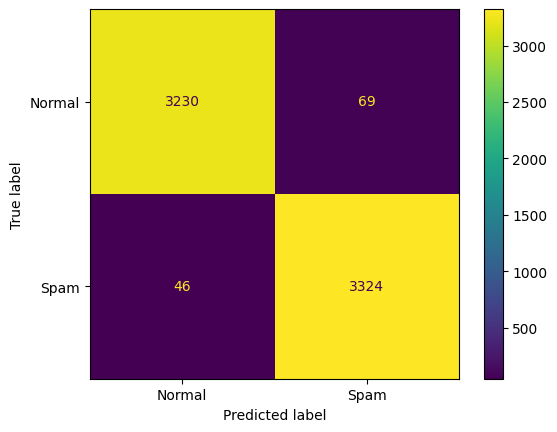

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Spam"]
).plot()

plt.show()

In [23]:
errors = pd.DataFrame({
    "message": X_test.to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

errors = errors[errors["Actual"] != errors["Predicted"]]

display(errors.head(10))

,message,Actual,Predicted
14,Request for approval of access credentials for...,0,1
22,salon packages for women men take a color remo...,0,1
27,wanderlust tuesdaysget instant off cashback on...,0,1
29,Your IRS refund reference #8OGZP7VEY9 - see de...,0,1
52,Why am I being blocked out of nowhere?,0,1
53,hi the order for o whitening mask with trackin...,0,1
77,"Hey Mom and Dad, just letting you know I've go...",1,0
90,"Greetings for Sunday's sale! Hurry, discounts ...",0,1
93,What were you in your past life? find out your...,1,0
114,You've successfully boosted your data plan wit...,0,1


In [24]:
false_positives = errors[
    (errors["Actual"] == 0) & (errors["Predicted"] == 1)
]

false_negatives = errors[
    (errors["Actual"] == 1) & (errors["Predicted"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

print(
    "False positives among normal messages:",
    round(len(false_positives) / (y_test == 0).sum() * 100, 2), "%"
)

print(
    "False negatives among spam messages:",
    round(len(false_negatives) / (y_test == 1).sum() * 100, 2), "%"
)

False positives: 1893
False negatives: 1029
False positives among normal messages: 2.88 %
False negatives among spam messages: 10.73 %


In [41]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import MultinomialNB

param_grid = {
    "alpha": [0.01, 0.1, 0.5, 1.0, 2.0]
}

grid_search = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_tfidf, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",MultinomialNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callable

In [42]:
print("Best alpha:", grid_search.best_params_["alpha"])
print("Best CV F1-score:", grid_search.best_score_)

Best alpha: 0.01
Best CV F1-score: 0.8621826295082181


In [43]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

best_nb_model = grid_search.best_estimator_

y_pred_tuned = best_nb_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_tuned, target_names=["Normal", "Spam"]))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tuned))

Accuracy: 0.9626641899960197

Classification Report:

              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98     65783
        Spam       0.82      0.91      0.86      9587

    accuracy                           0.96     75370
   macro avg       0.90      0.94      0.92     75370
weighted avg       0.97      0.96      0.96     75370

Confusion Matrix:
 [[63813  1970]
 [  844  8743]]


In [44]:
results = pd.DataFrame(grid_search.cv_results_)

display(
    results[[
        "param_alpha",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]].sort_values("rank_test_score")
)

,param_alpha,mean_test_score,std_test_score,rank_test_score
0,0.01,0.862183,0.000242,1
1,0.10,0.859601,0.000225,2
2,0.50,0.855625,0.000653,3
3,1.00,0.850922,0.000522,4
4,2.00,0.839783,0.000339,5


## Comparing Tuned vs Baseline Model:

In [46]:
from sklearn.metrics import confusion_matrix

print("Baseline confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nTuned confusion matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Baseline confusion matrix:
[[63890  1893]
 [ 1029  8558]]

Tuned confusion matrix:
[[63813  1970]
 [  844  8743]]


### saving the tuned model

In [50]:
import joblib

model_bundle = {
    "model": best_nb_model,
    "tfidf_vectorizer": tfidf
}

joblib.dump(model_bundle, "spam_nb_model.pkl")

print("Model bundle saved successfully!")

Model bundle saved successfully!


In [51]:
import joblib

loaded_bundle = joblib.load("spam_nb_model.pkl")

loaded_model = loaded_bundle["model"]
loaded_tfidf = loaded_bundle["tfidf_vectorizer"]

message = ["Congratulations! You have won a free prize. Click here to claim now."]

message_tfidf = loaded_tfidf.transform(message)
prediction = loaded_model.predict(message_tfidf)[0]

print("Message:", message[0])
print("Prediction:", "Spam" if prediction == 1 else "Normal")

Message: Congratulations! You have won a free prize. Click here to claim now.
Prediction: Spam
